## CL-2 (IR) Assignment 5: PageRank Algorithm
### Implement the PageRank Algorithm in Python.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

plt.rcParams["figure.figsize"] = (10, 6)

In [2]:
# Example directed web graph.
# Each key is a page and its list contains pages linked from it.
graph = {
    "A": ["B", "C"],
    "B": ["C", "D"],
    "C": ["A"],
    "D": ["C", "E"],
    "E": ["A", "D"]
}

print("Web graph:")
for page, links in graph.items():
    print(f"{page} -> {links}")

Web graph:
A -> ['B', 'C']
B -> ['C', 'D']
C -> ['A']
D -> ['C', 'E']
E -> ['A', 'D']


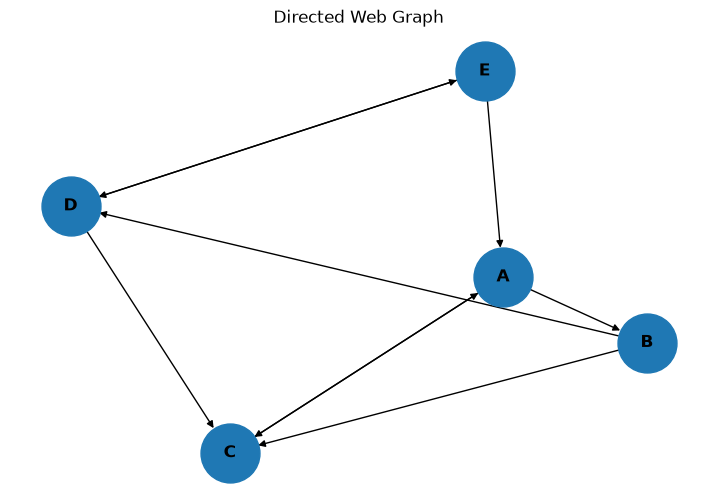

In [3]:
G = nx.DiGraph()

for source, destinations in graph.items():
    for destination in destinations:
        G.add_edge(source, destination)

pos = nx.spring_layout(G, seed=42)

plt.figure(figsize=(9, 6))
nx.draw_networkx(
    G,
    pos,
    with_labels=True,
    node_size=1800,
    arrows=True,
    font_weight="bold"
)
plt.title("Directed Web Graph")
plt.axis("off")
plt.show()

In [4]:
def pagerank(graph, damping=0.85, max_iterations=100, tolerance=1e-8):
    pages = list(graph.keys())
    n = len(pages)
    page_index = {page: i for i, page in enumerate(pages)}

    # Ensure every linked page is represented.
    for links in graph.values():
        for page in links:
            if page not in page_index:
                page_index[page] = len(pages)
                pages.append(page)

    n = len(pages)
    rank = np.ones(n) / n

    # Build incoming-link structure.
    incoming = {page: [] for page in pages}
    outgoing_count = {page: len(graph.get(page, [])) for page in pages}

    for source in pages:
        for destination in graph.get(source, []):
            incoming[destination].append(source)

    history = [rank.copy()]

    for iteration in range(1, max_iterations + 1):
        new_rank = np.ones(n) * ((1 - damping) / n)

        for page in pages:
            i = page_index[page]

            for source in incoming[page]:
                out_degree = outgoing_count.get(source, 0)

                if out_degree > 0:
                    new_rank[i] += damping * (
                        rank[page_index[source]] / out_degree
                    )

        # Handle dangling nodes by redistributing their rank uniformly.
        dangling_rank = sum(
            rank[page_index[p]]
            for p in pages
            if outgoing_count.get(p, 0) == 0
        )
        new_rank += damping * dangling_rank / n

        history.append(new_rank.copy())

        if np.linalg.norm(new_rank - rank, ord=1) < tolerance:
            rank = new_rank
            print(f"Converged after {iteration} iterations.")
            break

        rank = new_rank

    return {page: rank[page_index[page]] for page in pages}, history

scores, history = pagerank(graph)

results = (
    pd.DataFrame({
        "Page": list(scores.keys()),
        "PageRank": list(scores.values())
    })
    .sort_values("PageRank", ascending=False)
    .reset_index(drop=True)
)

results["Rank"] = np.arange(1, len(results) + 1)

display(results)

Converged after 45 iterations.


,Page,PageRank,Rank
0,A,0.316571,1
1,C,0.292920,2
2,B,0.164543,3
3,D,0.137520,4
4,E,0.088446,5


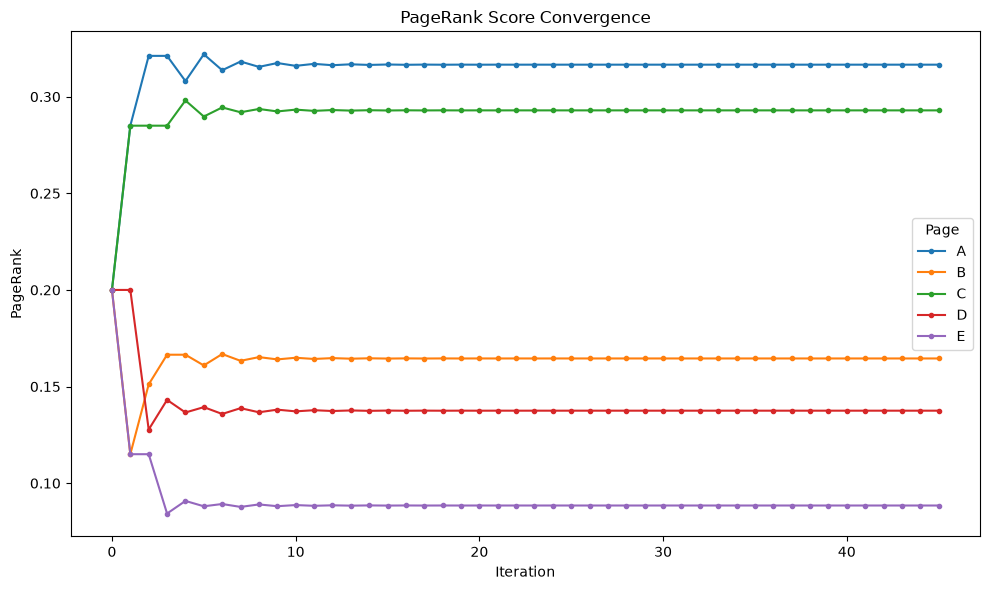

In [5]:
history_array = np.array(history)

plt.figure(figsize=(10, 6))
for i, page in enumerate(scores.keys()):
    plt.plot(history_array[:, i], marker=".", label=page)

plt.title("PageRank Score Convergence")
plt.xlabel("Iteration")
plt.ylabel("PageRank")
plt.legend(title="Page")
plt.tight_layout()
plt.show()

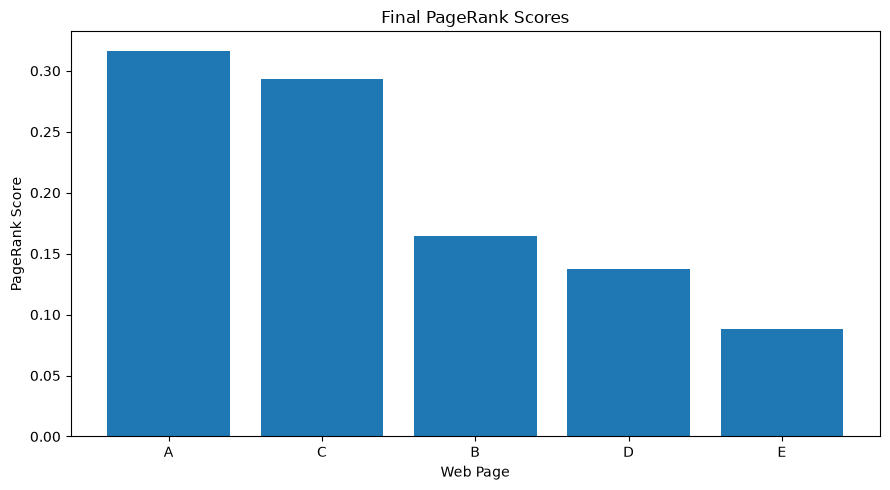

PageRank scores:


,Page,PageRank,Rank
0,A,0.316571,1
1,C,0.292920,2
2,B,0.164543,3
3,D,0.137520,4
4,E,0.088446,5


In [6]:
plt.figure(figsize=(9, 5))
plt.bar(results["Page"], results["PageRank"])
plt.title("Final PageRank Scores")
plt.xlabel("Web Page")
plt.ylabel("PageRank Score")
plt.tight_layout()
plt.show()

print("PageRank scores:")
display(results)

In [7]:
highest_page = results.iloc[0]["Page"]
highest_score = results.iloc[0]["PageRank"]

print(f"Highest PageRank in this graph: {highest_page}")
print(f"PageRank score: {highest_score:.6f}")

print("\nInterpretation:")
print("- A page receives a higher score when it is linked by pages that themselves have higher PageRank.")
print("- The damping factor models the probability that a user continues following links.")
print("- Iteration continues until the PageRank vector converges or the maximum iteration count is reached.")

Highest PageRank in this graph: A
PageRank score: 0.316571

Interpretation:
- A page receives a higher score when it is linked by pages that themselves have higher PageRank.
- The damping factor models the probability that a user continues following links.
- Iteration continues until the PageRank vector converges or the maximum iteration count is reached.
